<a href="https://colab.research.google.com/github/krjeyy/AI-ML-lab-experiments/blob/main/data_preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Original Dataset:
      Vehicle_Type  Vehicle_Age  Mileage  Engine_Temp   RPM  Oil_Pressure  \
0        Hatchback           10     7984           85  1144            36   
1            Sedan            5   132389           86  1660            34   
2              SUV           10   158617          101  2588            26   
3              SUV            5    54477           99  2762            39   
4            Sedan            3   122035          102  2146            41   
...            ...          ...      ...          ...   ...           ...   
11995        Sedan            9    50575           84  2241            41   
11996        Sedan           11    99075          103  1701            29   
11997    Hatchback            4   235129           88  1687            34   
11998          SUV            2   112534          101  1363            30   
11999        Sedan           11    63624           91  2509            33   

       Fuel_Consumption  Battery_Voltage  Brake_Pressure 

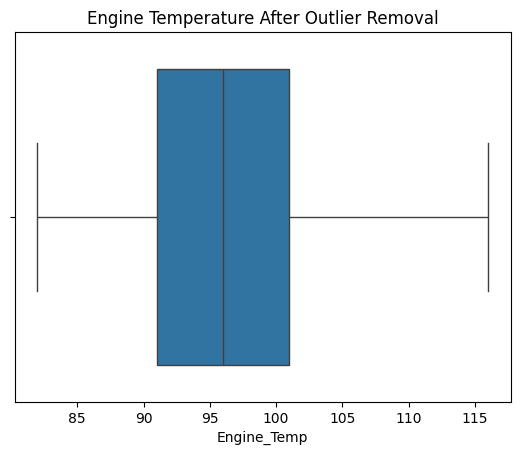


Dataset After Min-Max Normalization:
  Vehicle_Type  Vehicle_Age   Mileage  Engine_Temp       RPM  Oil_Pressure  \
0    Hatchback     0.818182  0.011986     0.088235  0.187586      0.636364   
1        Sedan     0.363636  0.519861     0.117647  0.365517      0.575758   
2          SUV     0.818182  0.626935     0.558824  0.685517      0.333333   
3          SUV     0.363636  0.201791     0.500000  0.745517      0.727273   
4        Sedan     0.181818  0.477592     0.588235  0.533103      0.787879   

   Fuel_Consumption  Battery_Voltage  Brake_Pressure  Tire_Pressure  
0          0.801932         0.863636            0.10          0.500  
1          0.570048         0.181818            0.45          0.625  
2          0.400966         0.663636            0.90          0.375  
3          0.371981         0.172727            0.20          0.125  
4          0.502415         0.354545            0.95          1.000  

Dataset After Z-score Standardization:
  Vehicle_Type  Vehicle_Age   Mil

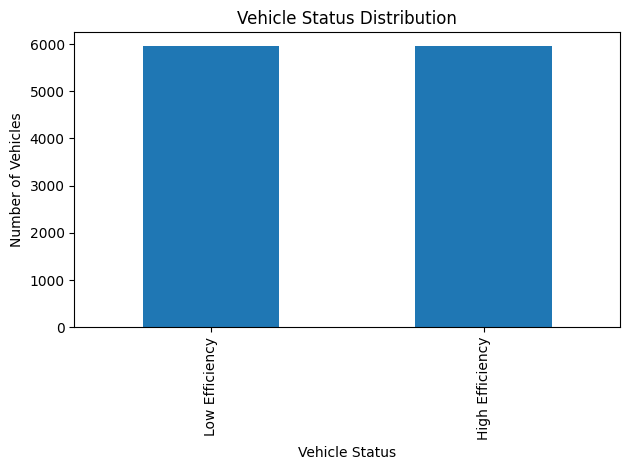


Class Distribution Before SMOTE:
Vehicle_Status
Low Efficiency     5951
High Efficiency    5951
Name: count, dtype: int64

Class Distribution After SMOTE:
Vehicle_Status
Low Efficiency     4761
High Efficiency    4761
Name: count, dtype: int64


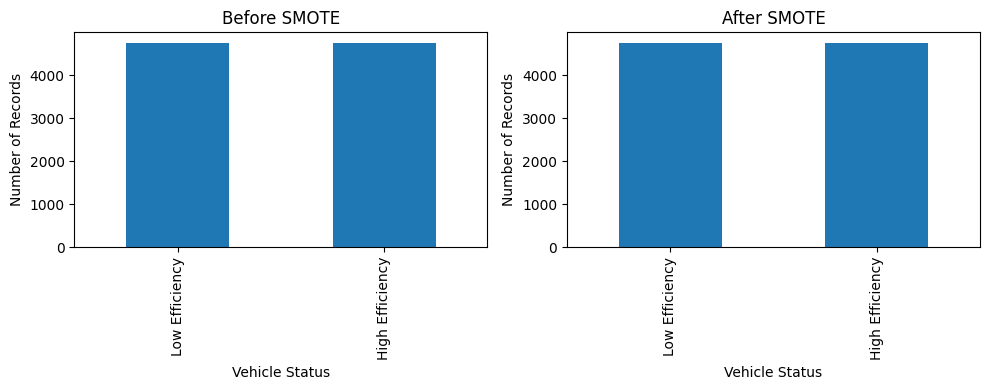

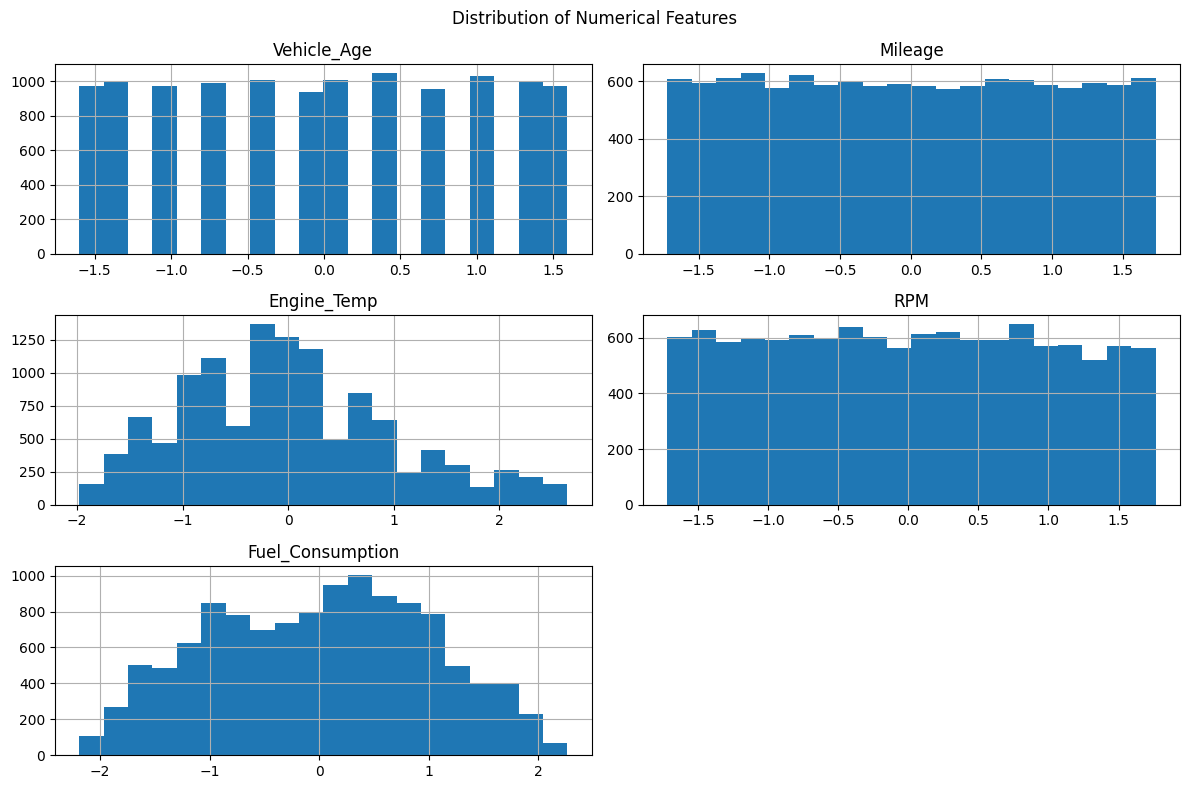

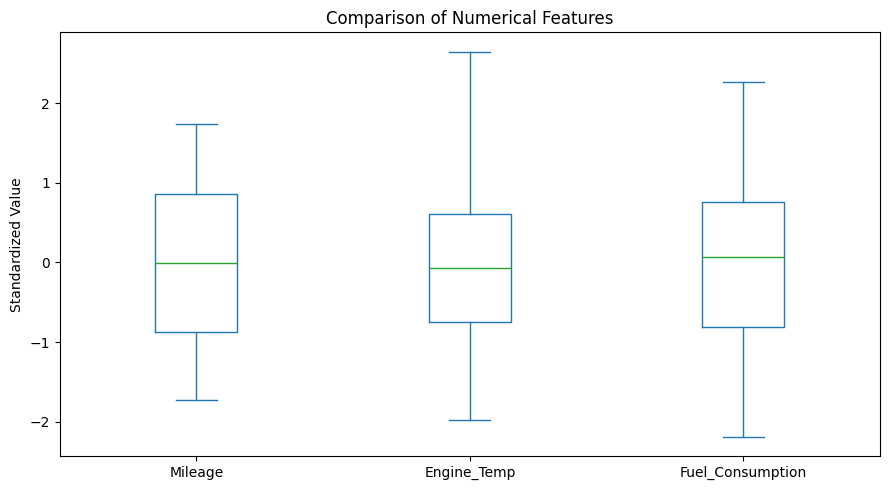


Processed Dataset Saved Successfully!

Final Dataset:
  Vehicle_Type  Vehicle_Age   Mileage  Engine_Temp       RPM  Oil_Pressure  \
0    Hatchback     1.012242 -1.679467    -1.570046 -1.066749      0.470386   
1        Sedan    -0.439411  0.074088    -1.434027 -0.446663      0.166977   
2          SUV     1.012242  0.443785     0.606251  0.668531     -1.046659   
3          SUV    -0.439411 -1.024123     0.334214  0.877630      0.925499   
4        Sedan    -1.020071 -0.071858     0.742269  0.137372      1.228908   

   Fuel_Consumption  Battery_Voltage  Brake_Pressure  Tire_Pressure  \
0          1.384383         1.249491       -1.304526      -0.024930   
1          0.350863        -1.109227       -0.144275       0.364678   
2         -0.402745         0.557600        1.347477      -0.414537   
3         -0.531935        -1.140676       -0.973026      -1.193753   
4          0.049420        -0.511685        1.513227       1.533502   

   Engine_Performance_Score  Vehicle_Efficiency  

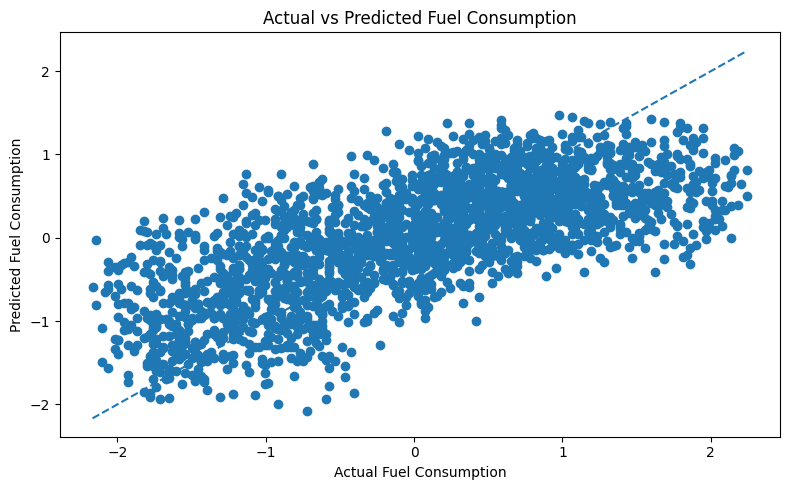


Program Completed Successfully!


In [ ]:

# ============================================================
# AI/ML LAB CYCLE 1 - DATA PREPROCESSING AND ANALYSIS
# Dataset: carsensor.csv
# ============================================================

# Step 1: Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from imblearn.over_sampling import SMOTE

# Step 2: Load the dataset
df = pd.read_csv("carsensor.csv")

print("Original Dataset:")
print(df)

print("\nFirst 5 Records:")
print(df.head())

print("\nLast 5 Records:")
print(df.tail())

print("\nRandom 5 Records:")
print(df.sample(min(5, len(df)), random_state=42))


# Step 3: Find and display missing values
print("\nMissing Values in Each Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())


# Step 4: Handle missing values
num_cols = [
    'Vehicle_Age', 'Mileage', 'Engine_Temp', 'RPM',
    'Oil_Pressure', 'Fuel_Consumption', 'Battery_Voltage',
    'Brake_Pressure', 'Tire_Pressure'
]

# Use only numerical columns that exist in the dataset
num_cols = [col for col in num_cols if col in df.columns]

# Fill numerical missing values with the mean
df[num_cols] = df[num_cols].fillna(df[num_cols].mean())

# Fill categorical missing values with the mode
if 'Vehicle_Type' in df.columns and df['Vehicle_Type'].isnull().any():
    df['Vehicle_Type'] = df['Vehicle_Type'].fillna(
        df['Vehicle_Type'].mode()[0]
    )

print("\nMissing Values After Handling:")
print(df.isnull().sum())


# Step 5: Detect and remove duplicate records
print("\nNumber of Duplicate Rows Before Removal:")
print(df.duplicated().sum())

df = df.drop_duplicates().copy()

print("\nNumber of Duplicate Rows After Removal:")
print(df.duplicated().sum())


# Step 6: Detect outliers using the IQR method
if 'Engine_Temp' in df.columns:
    Q1 = df['Engine_Temp'].quantile(0.25)
    Q3 = df['Engine_Temp'].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df['Engine_Temp'] < lower_bound) |
        (df['Engine_Temp'] > upper_bound)
    ]

    print("\nEngine Temperature Outliers:")
    print(outliers)

    print("\nNumber of Engine Temperature Outliers:")
    print(len(outliers))

    # Remove outliers
    df = df[
        (df['Engine_Temp'] >= lower_bound) &
        (df['Engine_Temp'] <= upper_bound)
    ].copy()

    print("\nDataset After Removing Engine Temperature Outliers:")
    print(df.head())

    # Display box plot after removing outliers
    sns.boxplot(x=df['Engine_Temp'])
    plt.title("Engine Temperature After Outlier Removal")
    plt.show()


# Step 7: Min-Max Normalization
# Scales numerical values to the range 0 to 1
minmax_scaler = MinMaxScaler()

df[num_cols] = minmax_scaler.fit_transform(df[num_cols])

print("\nDataset After Min-Max Normalization:")
print(df.head())


# Step 8: Z-score Standardization
# Transforms numerical values to have approximately
# mean 0 and standard deviation 1
standard_scaler = StandardScaler()

df[num_cols] = standard_scaler.fit_transform(df[num_cols])

print("\nDataset After Z-score Standardization:")
print(df.head())


# Step 9: Convert Boolean values into integers
bool_cols = df.select_dtypes(include=['bool']).columns

df[bool_cols] = df[bool_cols].astype(int)

print("\nBoolean Columns Converted to Integers:")
print(df.dtypes)


# Step 10: Display descriptive statistics
print("\nDescriptive Statistics:")
print(df.describe())


# Step 11: Check duplicate rows again
print("\nDuplicate Rows in Processed Dataset:")
print(df.duplicated().sum())


# Step 12: Check for infinite values
print("\nInfinite Values in Each Numerical Column:")
print(
    df.select_dtypes(include=np.number)
      .isin([np.inf, -np.inf])
      .sum()
)

# Replace infinite values with NaN
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# Fill any new numerical missing values
numeric_columns = df.select_dtypes(include=np.number).columns
df[numeric_columns] = df[numeric_columns].fillna(
    df[numeric_columns].mean()
)


# Step 13: Feature Engineering
# Create new features using existing numerical columns

if all(col in df.columns for col in ['RPM', 'Engine_Temp']):
    df['Engine_Performance_Score'] = (
        df['RPM'] / (df['Engine_Temp'].abs() + 1)
    )

if all(col in df.columns for col in ['Mileage', 'Fuel_Consumption']):
    df['Vehicle_Efficiency'] = (
        df['Mileage'] / (df['Fuel_Consumption'].abs() + 1)
    )

pressure_cols = [
    col for col in ['Oil_Pressure', 'Brake_Pressure', 'Tire_Pressure']
    if col in df.columns
]

if pressure_cols:
    df['Average_Pressure'] = df[pressure_cols].mean(axis=1)

print("\nDataset After Feature Engineering:")
print(df.head())


# Step 14: Convert any Boolean columns created during processing
bool_cols = df.select_dtypes(include=['bool']).columns
df[bool_cols] = df[bool_cols].astype(int)


# Step 15: Detect and remove outliers from engineered features
engineered_cols = [
    col for col in [
        'Engine_Performance_Score',
        'Vehicle_Efficiency',
        'Average_Pressure'
    ]
    if col in df.columns
]

for col in engineered_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ).sum()

    print(f"\nOutliers in {col}: {outlier_count}")

    df = df[
        (df[col] >= lower_bound) &
        (df[col] <= upper_bound)
    ].copy()

print("\nDataset After Removing Engineered Feature Outliers:")
print(df.head())


# Step 16: Create Vehicle_Status
# Vehicles with efficiency below the median are classified
# as Low Efficiency; the others are classified as High Efficiency

if 'Vehicle_Efficiency' in df.columns:
    median_efficiency = df['Vehicle_Efficiency'].median()

    df['Vehicle_Status'] = np.where(
        df['Vehicle_Efficiency'] < median_efficiency,
        'Low Efficiency',
        'High Efficiency'
    )

    print("\nVehicle Status Distribution:")
    print(df['Vehicle_Status'].value_counts())

    # Display the distribution
    df['Vehicle_Status'].value_counts().plot(
        kind='bar',
        title='Vehicle Status Distribution'
    )
    plt.xlabel("Vehicle Status")
    plt.ylabel("Number of Vehicles")
    plt.tight_layout()
    plt.show()


# Step 17: Prepare data for SMOTE
# SMOTE is used to balance the classes in the target variable

if 'Vehicle_Status' in df.columns:
    # Exclude the target and non-numeric columns from the features
    X = df.drop(columns=['Vehicle_Status'])
    X = X.select_dtypes(include=np.number)

    y = df['Vehicle_Status']

    # Remove rows with any remaining invalid values
    valid_rows = X.notna().all(axis=1) & y.notna()

    X = X.loc[valid_rows]
    y = y.loc[valid_rows]

    print("\nClass Distribution Before SMOTE:")
    print(y.value_counts())

    # SMOTE requires at least two classes and enough samples
    # in the minority class
    if y.nunique() >= 2 and y.value_counts().min() >= 2:
        X_train, X_test, y_train, y_test = train_test_split(
            X,
            y,
            test_size=0.2,
            random_state=42,
            stratify=y
        )

        minority_count = y_train.value_counts().min()

        # Set k_neighbors so SMOTE works with smaller datasets too
        smote = SMOTE(
            random_state=42,
            k_neighbors=min(5, minority_count - 1)
        )

        X_train_smote, y_train_smote = smote.fit_resample(
            X_train,
            y_train
        )

        print("\nClass Distribution After SMOTE:")
        print(y_train_smote.value_counts())

        # Compare class distribution before and after SMOTE
        fig, axes = plt.subplots(1, 2, figsize=(10, 4))

        y_train.value_counts().plot(
            kind='bar',
            ax=axes[0],
            title='Before SMOTE'
        )

        y_train_smote.value_counts().plot(
            kind='bar',
            ax=axes[1],
            title='After SMOTE'
        )

        axes[0].set_xlabel("Vehicle Status")
        axes[1].set_xlabel("Vehicle Status")
        axes[0].set_ylabel("Number of Records")
        axes[1].set_ylabel("Number of Records")

        plt.tight_layout()
        plt.show()

    else:
        print(
            "\nSMOTE was skipped because there are not enough "
            "samples in each class."
        )


# Step 18: Display histograms of numerical features
hist_cols = [
    col for col in [
        'Vehicle_Age',
        'Mileage',
        'Engine_Temp',
        'RPM',
        'Fuel_Consumption'
    ]
    if col in df.columns
]

if hist_cols:
    df[hist_cols].hist(figsize=(12, 8), bins=20)
    plt.suptitle("Distribution of Numerical Features")
    plt.tight_layout()
    plt.show()


# Step 19: Compare selected numerical features
compare_cols = [
    col for col in [
        'Mileage',
        'Engine_Temp',
        'Fuel_Consumption'
    ]
    if col in df.columns
]

if compare_cols:
    df[compare_cols].plot(
        kind='box',
        figsize=(9, 5),
        title='Comparison of Numerical Features'
    )
    plt.ylabel("Standardized Value")
    plt.tight_layout()
    plt.show()


# Step 20: Save the processed dataset
# This overwrites carsensor.csv if the input file has the same name.
# Use a different filename if you want to preserve the original dataset.

df.to_csv("carsensor.csv", index=False)

print("\nProcessed Dataset Saved Successfully!")
print("\nFinal Dataset:")
print(df.head())

print("\nFinal Dataset Shape:")
print(df.shape)


# Step 21: Linear Regression
# Predict Fuel_Consumption using selected numerical features

target = 'Fuel_Consumption'

feature_candidates = [
    'Vehicle_Age',
    'Mileage',
    'Engine_Temp',
    'RPM',
    'Oil_Pressure',
    'Battery_Voltage',
    'Brake_Pressure',
    'Tire_Pressure'
]

features = [
    col for col in feature_candidates
    if col in df.columns and col != target
]

if target in df.columns and features and len(df) >= 2:
    # Select features and target
    model_data = df[features + [target]].replace(
        [np.inf, -np.inf], np.nan
    ).dropna()

    X = model_data[features]
    y = model_data[target]

    if len(model_data) >= 2:
        X_train, X_test, y_train, y_test = train_test_split(
            X,
            y,
            test_size=0.2,
            random_state=42
        )

        # Create and train the Linear Regression model
        model = LinearRegression()
        model.fit(X_train, y_train)

        # Make predictions
        y_pred = model.predict(X_test)

        # Display actual and predicted values
        comparison = pd.DataFrame({
            'Actual Fuel Consumption': y_test.values,
            'Predicted Fuel Consumption': y_pred
        })

        print("\nActual vs Predicted Fuel Consumption:")
        print(comparison.head())

        # Evaluate the model
        print("\nLinear Regression Evaluation:")
        print(
            "Mean Absolute Error:",
            mean_absolute_error(y_test, y_pred)
        )

        print(
            "Mean Squared Error:",
            mean_squared_error(y_test, y_pred)
        )

        print(
            "R2 Score:",
            r2_score(y_test, y_pred)
            if len(y_test) >= 2
            else "Not enough test records to calculate R2"
        )

        # Plot actual and predicted values
        plt.figure(figsize=(8, 5))

        plt.scatter(
            y_test,
            y_pred
        )

        plt.xlabel("Actual Fuel Consumption")
        plt.ylabel("Predicted Fuel Consumption")
        plt.title("Actual vs Predicted Fuel Consumption")

        # Reference line
        min_value = min(y_test.min(), y_pred.min())
        max_value = max(y_test.max(), y_pred.max())

        plt.plot(
            [min_value, max_value],
            [min_value, max_value],
            linestyle='--'
        )

        plt.tight_layout()
        plt.show()

    else:
        print("\nNot enough valid records for Linear Regression.")

else:
    print(
        "\nLinear Regression was skipped. Check whether "
        "'Fuel_Consumption' and the required feature columns exist."
    )

print("\nProgram Completed Successfully!")
